In [46]:
import torch
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

In [47]:
iris = load_iris()

X = iris.data
y = iris.target

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (150, 4)
y shape: (150,)


In [48]:
X = torch.tensor(X, dtype=torch.float32)

y = torch.tensor(y, dtype=torch.long)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: torch.Size([150, 4])
y shape: torch.Size([150])


In [49]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = torch.tensor(X_scaled, dtype=torch.float32)

print("X_scaled shape:", X_scaled.shape)


X_scaled shape: torch.Size([150, 4])


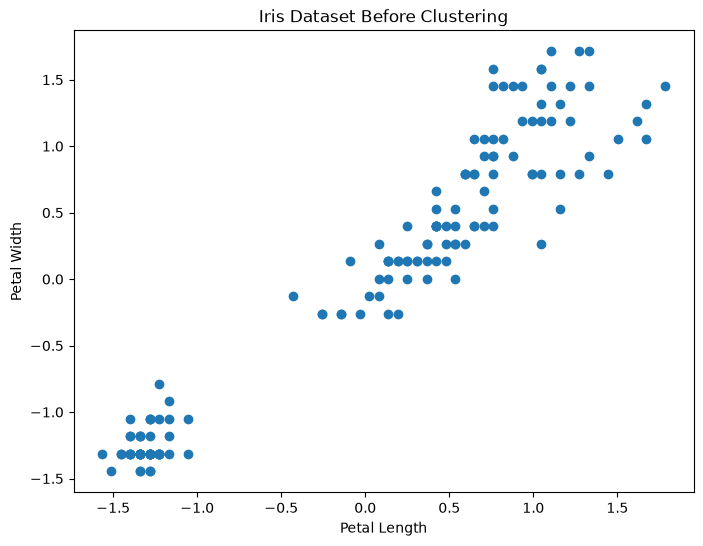

In [50]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_scaled[:, 2],
    X_scaled[:, 3]
)

plt.xlabel("Petal Length")
plt.ylabel("Petal Width")

plt.title(
    "Iris Dataset Before Clustering"
)

plt.show()

In [51]:
K = 3

print("Number of clusters:", K)

def initialize_centroids(X, k):

    indices = torch.randperm(X.shape[0])[:k]

    centroids = X[indices]

    return centroids

Number of clusters: 3


In [52]:
torch.manual_seed(42)

centroids = initialize_centroids(
    X_scaled,
    K
)

print("Centroids:")
print(centroids)

print(
    "Centroid shape:",
    centroids.shape
)

Centroids:
tensor([[-1.7489e+00,  3.2841e-01, -1.3971e+00, -1.3154e+00],
        [-1.7367e-01, -1.3198e-01,  2.5122e-01,  8.7762e-04],
        [-1.2642e+00,  9.8217e-02, -1.2266e+00, -1.3154e+00]])
Centroid shape: torch.Size([3, 4])


In [53]:
def calulate_distances(X, centroids):

    distances = torch.cdist(X, centroids)

    return distances

In [54]:
distances = calulate_distances(X_scaled, centroids)

print("Distances shape:", distances.shape)

Distances shape: torch.Size([150, 3])


In [55]:
def assign_clusters(distances):

    cluster_assignments = torch.argmin(distances,dim=1)

    return cluster_assignments

In [56]:
clusters = assign_clusters(distances)

print(clusters[:20])

tensor([2, 2, 2, 2, 0, 2, 0, 2, 2, 2, 2, 0, 2, 0, 2, 0, 2, 2, 2, 0])


In [57]:
def update_centroids(X, clusters, k):

    new_centroids = torch.zeros((k, X.shape[1]))

    new_centroids = []

    for k in range(K):
        cluster_points = X[clusters == k]

        if len(cluster_points) == 0:
            new_centroids.append(torch.zeros(X.shape[1])).squeeze(0)

        else:
            new_centroid = cluster_points.mean(dim=0)

            new_centroids.append(new_centroid)

    return torch.stack(new_centroids)

In [60]:
new_centroids = update_centroids(X_scaled, clusters, K)

print("New centroids:", new_centroids)


New centroids: tensor([[-1.1592,  1.2645, -1.3289, -1.2891],
        [ 0.5073, -0.4266,  0.6525,  0.6274],
        [-0.9526,  0.6770, -1.2948, -1.2402]])


In [61]:
def kmeans(X,K,max_iterations=100,tolerance=1e-4):

    # Step 1: initialize centroids
    centroids = initialize_centroids(X, K)

    for iteration in range(max_iterations):

        # Step 2: calculate distances
        distances = calculate_distances( X, centroids)

        # Step 3: assign clusters
        clusters = assign_clusters(
            distances
        )

        # Step 4: update centroids
        new_centroids = update_centroids(
            X,
            clusters,
            K
        )

        # Check convergence
        centroid_shift = torch.norm(
            new_centroids - centroids
        )

        centroids = new_centroids

        print(
            f"Iteration {iteration + 1}: "
            f"Shift = {centroid_shift.item():.6f}"
        )

        if centroid_shift < tolerance:

            print(
                "Converged!"
            )

            break

    return clusters, centroids

In [62]:
torch.manual_seed(42)

clusters, centroids = kmeans(
    X_scaled,
    K=3,
    max_iterations=100
)

NameError: name 'calculate_distances' is not defined

In [ ]:
# Fix K-Means implementation and compatible naming
def calculate_distances(X, centroids):
    return torch.cdist(X, centroids)

def assign_clusters(distances):
    return torch.argmin(distances, dim=1)

def update_centroids(X, clusters, k):
    new_centroids = []
    for cluster_id in range(k):
        cluster_points = X[clusters == cluster_id]

        if len(cluster_points) == 0:
            new_centroids.append(torch.zeros(X.shape[1], dtype=X.dtype))
        else:
            new_centroids.append(cluster_points.mean(dim=0))

    return torch.stack(new_centroids)

def initialize_centroids(X, k):
    indices = torch.randperm(X.shape[0])[:k]
    return X[indices]

def kmeans(X, K, max_iterations=100, tolerance=1e-4):
    centroids = initialize_centroids(X, K)

    for iteration in range(max_iterations):
        distances = calculate_distances(X, centroids)
        clusters = assign_clusters(distances)
        new_centroids = update_centroids(X, clusters, K)

        centroid_shift = torch.norm(new_centroids - centroids)
        centroids = new_centroids

        print(f"Iteration {iteration + 1}: Shift = {centroid_shift.item():.6f}")

        if centroid_shift < tolerance:
            print("Converged!")
            break

    return clusters, centroids


torch.manual_seed(42)
clusters, centroids = kmeans(X_scaled, K=3, max_iterations=100)

print("Final clusters:", clusters)
print("Final centroids:\n", centroids)